In [1]:
import torch
print(3)

3


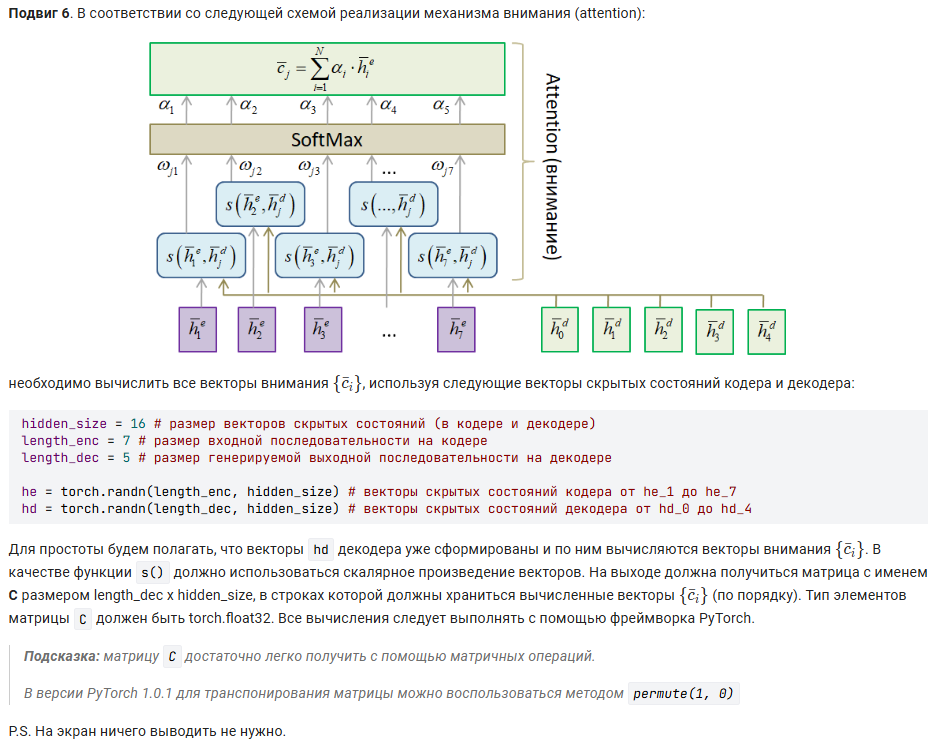

In [21]:
import torch

torch.manual_seed(1) # фиксация зерна датчика случайных чисел (не менять)

# порядок этих строк в программе не менять
hidden_size = 16 # размер векторов скрытых состояний (в кодере и декодере)
length_enc = 7 # размер входной последовательности на кодере
length_dec = 5 # размер генерируемой выходной последовательности на декодере

he = torch.randn(length_enc, hidden_size) # векторы скрытых состояний кодера от he_1 до he_7
hd = torch.randn(length_dec, hidden_size) # векторы скрытых состояний декодера от hd_0 до hd_4

# здесь продолжайте программу

C = torch.zeros(length_dec, hidden_size)

w = he @ hd.permute(1, 0) # [7, 16] @ [16, 5] = [7, 5]
a = torch.softmax(w, dim=0) # length_enc x length_dec
C = a.permute(1, 0) @ he # [5, 7] @ [7, 16] = [5, 16]

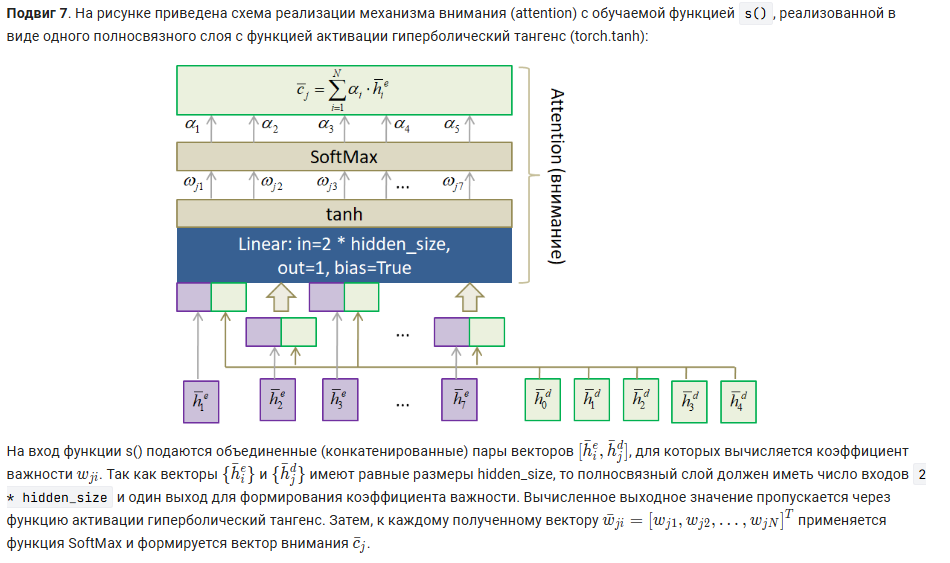
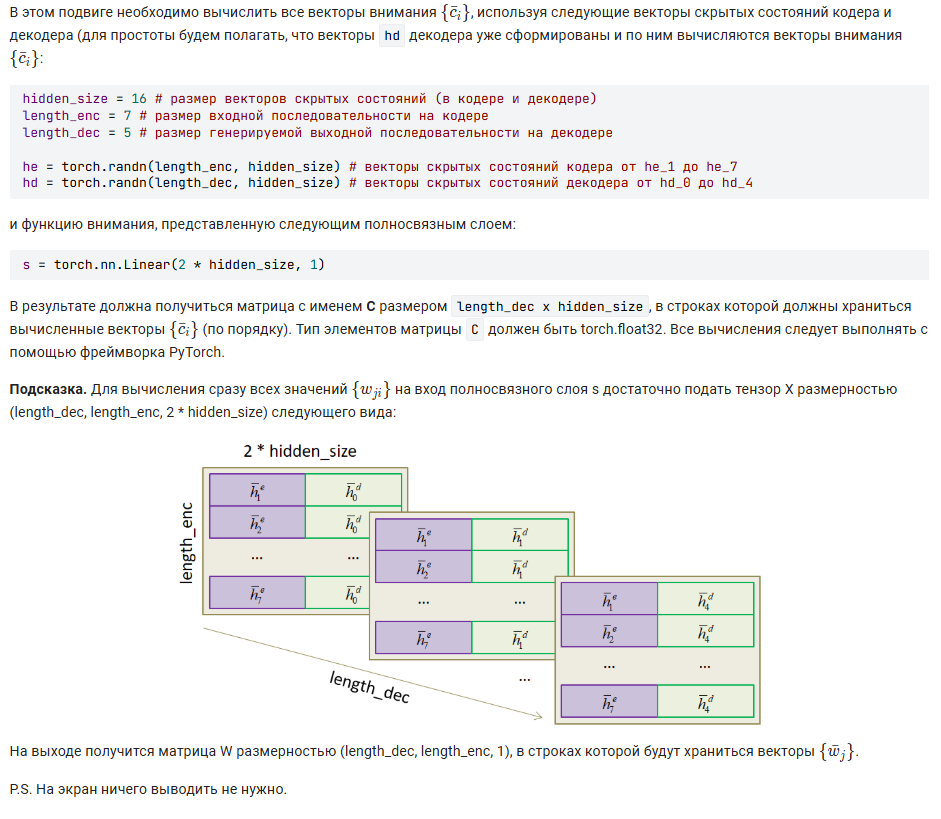

In [60]:
import torch

torch.manual_seed(1) # фиксация зерна датчика случайных чисел (не менять)

# порядок этих строк в программе не менять
hidden_size = 16 # размер векторов скрытых состояний (в кодере и декодере)
length_enc = 7 # размер входной последовательности на кодере
length_dec = 5 # размер генерируемой выходной последовательности на декодере

he = torch.randn(length_enc, hidden_size) # векторы скрытых состояний кодера от he_1 до he_7
hd = torch.randn(length_dec, hidden_size) # векторы скрытых состояний декодера от hd_0 до hd_4

s = torch.nn.Linear(2 * hidden_size, 1) # функция s(); в программе не менять

# здесь продолжайте программу

he_exp = he.unsqueeze(1).expand(-1, 5, -1)  # [7, 5, 16]
hd_exp = hd.unsqueeze(0).expand(7, -1, -1)  # [7, 5, 16]

x = torch.cat([he_exp, hd_exp], dim=-1)     # [7, 5, 32]

w = torch.tanh(s(x))
a = torch.softmax(w, dim=0).squeeze(2) # [7, 5]
C = a.permute(1, 0) @ he

C.shape




torch.Size([5, 16])

In [56]:
he_exp.shape

torch.Size([7, 5, 16])